# Bus travel time prediction: ML vs historical averages
**CSC340 Artificial Intelligence, SIT KMUTT.**

**Research question:** Can a machine-learning model predict bus travel time between stops more accurately than the historical-average methods a commuter uses today?

* Regression (main): travel time of one stop-to-stop segment, in seconds.
* Classification (derived): an 8-stop journey is **Late** if it takes more than 1.2 × its usual (median) time.
* The *Wait / motorcycle taxi / Grab* recommendation in the app is a **rule** on top of the prediction, not ML.

Data: Astana (Kazakhstan) bus GPS, Zenodo DOI 10.5281/zenodo.15769359 (Mansurova et al., 2025), CC BY 4.0. Weather: Open-Meteo historical API.

This notebook follows the same steps as `src/prepare.py` and `src/train.py`. Model training and the hyper-parameter search (~14 min on a laptop) run in `src/train.py`; here we load those saved models and **re-compute every test metric** so the numbers can be checked.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from features import FEATURES, FEATURES_R1
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
DATA, REP, MOD = ROOT / "data", ROOT / "reports", ROOT / "models"

## 1. Look at the raw data first (verify the real columns)

In [2]:
raw = pd.read_csv(DATA / "segment_level_data.csv")
print("shape:", raw.shape)
print(raw.dtypes)
raw.head()

shape: (785976, 15)
date                       str
deviceid                 int64
direction                int64
segment                  int64
start_point              int64
end_point                int64
start_time                 str
run_time_in_seconds      int64
dwell_time_in_seconds    int64
arrival_time               str
departure_time             str
trip_id                  int64
device_guid                str
start_guid                 str
end_guid                   str
dtype: object


,date,deviceid,direction,segment,start_point,end_point,start_time,run_time_in_seconds,dwell_time_in_seconds,arrival_time,departure_time,trip_id,device_guid,start_guid,end_guid
0,2024-08-01,1038,2,39,2037,2038,2024-08-01 17:38:47,279,0,2024-08-01 17:43:26,2024-08-01 17:43:26,2306,04326bab-ee84-491d-8b3c-db5be265e756,3d570ad2-db12-47d1-b15e-a33dfa403c56,9c39bef4-78ba-41cc-af86-4e9cec3e06dd
1,2024-08-01,1038,2,6,2006,2004,2024-08-01 16:44:26,52,0,2024-08-01 16:45:18,2024-08-01 16:45:18,2306,04326bab-ee84-491d-8b3c-db5be265e756,88b7ca3b-3501-4efe-b33f-701453ffa277,28764497-a568-434f-83dd-932a3c91e199
2,2024-09-11,780,2,5,2004,2006,2024-09-11 16:16:14,37,0,2024-09-11 16:16:51,2024-09-11 16:16:51,19707,ad9f7b2b-5776-4de9-9b73-e28b5fe585fa,28764497-a568-434f-83dd-932a3c91e199,88b7ca3b-3501-4efe-b33f-701453ffa277
3,2024-09-11,789,2,5,2004,2006,2024-09-11 18:22:42,54,0,2024-09-11 18:23:36,2024-09-11 18:23:36,19767,998bdc88-e13b-41fc-951e-7dd31ae1179b,28764497-a568-434f-83dd-932a3c91e199,88b7ca3b-3501-4efe-b33f-701453ffa277
4,2024-09-11,791,2,5,2006,2004,2024-09-11 18:41:49,49,0,2024-09-11 18:42:38,2024-09-11 18:42:38,19777,1c2bf601-811b-4623-a976-bdc87dff3b3b,88b7ca3b-3501-4efe-b33f-701453ffa277,28764497-a568-434f-83dd-932a3c91e199


In [3]:
print("nulls per column:\n", raw.isna().sum())
print("dates:", raw.date.min(), "to", raw.date.max(), "|", raw.date.nunique(), "days")
print("trips:", raw.trip_id.nunique(), "| buses:", raw.deviceid.nunique(), "| stops:", pd.concat([raw.start_point, raw.end_point]).nunique())
raw.run_time_in_seconds.describe()

nulls per column:
 date                     0
deviceid                 0
direction                0
segment                  0
start_point              0
end_point                0
start_time               0
run_time_in_seconds      0
dwell_time_in_seconds    0
arrival_time             0
departure_time           0
trip_id                  0
device_guid              0
start_guid               0
end_guid                 0
dtype: int64
dates: 2024-07-29 to 2024-09-21 | 55 days
trips: 19769 | buses: 148 | stops: 201


count    785976.000000
mean        105.602788
std         188.425612
min           0.000000
25%          42.000000
50%          70.000000
75%         113.000000
max       19140.000000
Name: run_time_in_seconds, dtype: float64

**Findings that changed the plan**
* There is **no `route_id`** column (the paper lists one). We infer the route by clustering trips on the set of stops they visit (KMeans, k = 3 per direction). Each direction-1 cluster shares buses with exactly one direction-2 cluster, which gives 3 clean routes, called **A, B, C**. The file does not say which one is official route 10, 12 or 46.
* `segment` is the *position* along a trip, not a fixed stop pair. A physical segment is (`start_point`, `end_point`).
* `run_time = arrival - start` and `dwell = departure - arrival` hold for 100% of rows.

In [4]:
print("run_time == arrival - start:", ((pd.to_datetime(raw.arrival_time) - pd.to_datetime(raw.start_time)).dt.total_seconds() == raw.run_time_in_seconds).mean())
del raw

run_time == arrival - start: 1.0


## 2. Cleaning and feature engineering (`src/prepare.py`)

In [5]:
import prepare
prepare.main()

Loading raw data ...


  shape (785976, 15)


Cleaning ...
  duplicates                   removed       0  -> 785,976  (same trip, stop pair and start time)
  run_time <= 0                removed     925  -> 785,051  (impossible travel time)


  run_time > 3600s             removed     105  -> 784,946  (multi-hour gap = GPS/logging error)
  start == end stop            removed       0  -> 784,946  (not a real segment)
Inferring routes ...


  route pairing (dir1, dir2, shared bus-days): [('1-1', '2-1', 1022), ('1-0', '2-0', 932), ('1-2', '2-2', 627)]


  rare segments (<50 in train) removed   5,011  -> 779,935  (detours / rare stop pairs)
  capped 15,537 extreme values per segment (kept rows)
Building features ...


  features: (779935, 39), train 592,198, test 187,737
  null counts: {}
Building journeys (features as of journey start) ...


  journeys: 89,516, Late rate train 17.5%, test 18.1%


Done.


In [6]:
pd.read_csv(REP / "cleaning_log.csv")

,step,rows_before,rows_after,rows_removed,reason
0,duplicates,785976,785976,0,"same trip, stop pair and start time"
1,run_time <= 0,785976,785051,925,impossible travel time
2,run_time > 3600s,785051,784946,105,multi-hour gap = GPS/logging error
3,start == end stop,784946,784946,0,not a real segment
4,rare segments (<50 in train),784946,779935,5011,detours / rare stop pairs
5,"cap per segment (1st-99th pct, train)",779935,779935,0,"15,537 values capped, not removed"


In [7]:
df = pd.read_parquet(DATA / "features.parquet")
tr, te = df[df.is_train], df[~df.is_train]
print(f"train: {tr.date.min():%d %b} - {tr.date.max():%d %b} {len(tr):,} rows | test: {te.date.min():%d %b} - {te.date.max():%d %b} {len(te):,} rows")
df.groupby("route").agg(rows=("run_time", "size"), trips=("trip_id", "nunique"), segments=("seg_key", "nunique"))

train: 29 Jul - 08 Sep 592,198 rows | test: 09 Sep - 21 Sep 187,737 rows


,rows,trips,segments
route,,,
A,332397,8139,141
B,241569,6480,119
C,205969,5150,137


**Features (all known before the bus starts the segment, nothing from the future):**

| Group | Features |
|---|---|
| Time | hour, minute of day, day of week, weekend, Kazakhstan public holiday |
| Place | route, direction, segment id, position on the trip |
| History (train only) | segment average, segment × hour average |
| Current traffic | previous bus's run time on the same segment (it must have **arrived before** this bus started), its dwell, how old that information is, ratio to usual |
| Waiting | headway: minutes since the previous bus of the same route left this stop |
| Weather | rain (mm, hourly), temperature |
| Round 2 | route traffic: slowness of all buses on the route in the last 15 min · bus delay: how slow this bus has been on its earlier segments |

Split by **time**: first 6 weeks train (29 Jul - 8 Sep), last 2 weeks test (9 - 21 Sep). No random split.

## 3. Exploratory analysis

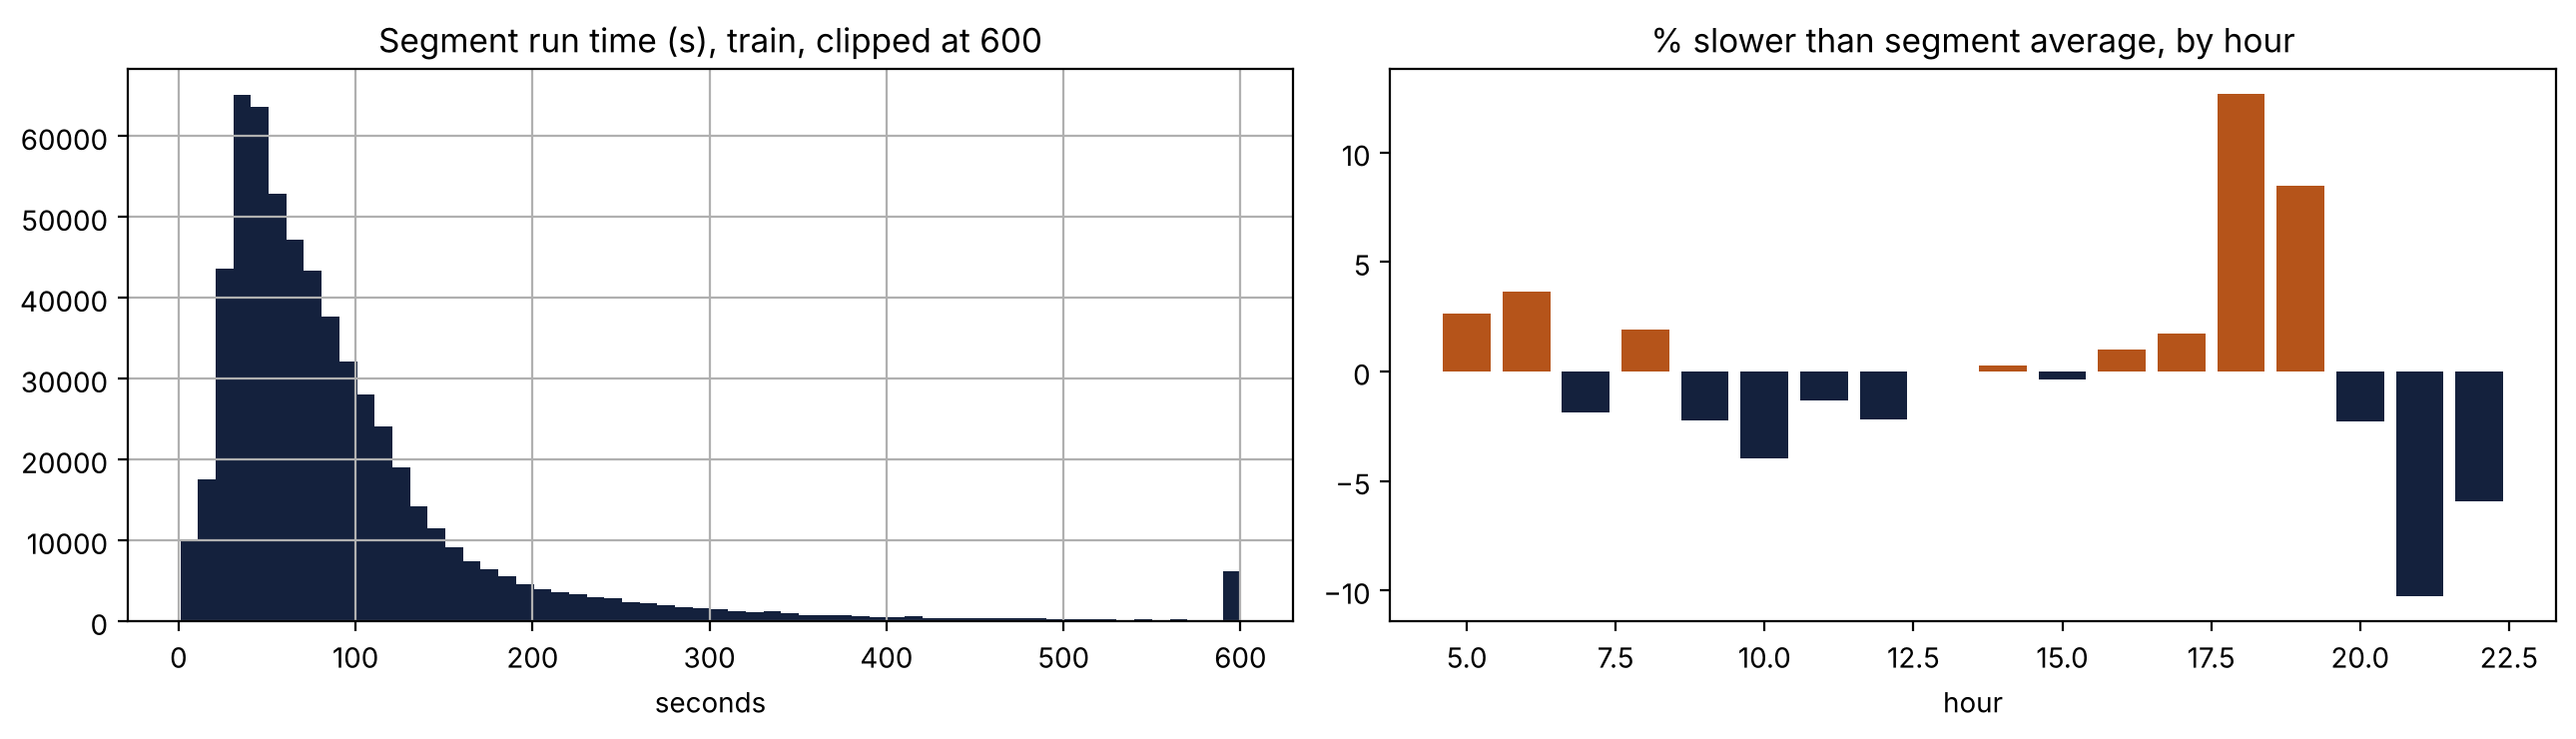

run_time         1.000
seg_mean         0.688
seg_hour_mean    0.798
lag_run          0.698
route_traffic    0.053
bus_delay        0.015
headway_min     -0.022
rain_mm          0.002
temp_c           0.011
Name: run_time, dtype: float64

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
tr.run_time.clip(upper=600).hist(bins=60, ax=ax[0], color="#14213D"); ax[0].set_title("Segment run time (s), train, clipped at 600"); ax[0].set_xlabel("seconds")
r = tr.assign(ratio=tr.run_time / tr.seg_mean).groupby("hour").ratio.mean()
ax[1].bar(r.index, (r - 1) * 100, color=["#B5541A" if v > 1 else "#14213D" for v in r]); ax[1].set_title("% slower than segment average, by hour"); ax[1].set_xlabel("hour")
plt.tight_layout(); plt.show()
tr[["run_time", "seg_mean", "seg_hour_mean", "lag_run", "route_traffic", "bus_delay", "headway_min", "rain_mm", "temp_c"]].corr()["run_time"].round(3)

Travel time is right-skewed (a few very slow trips), and the same segment is ~13% slower at 18:00 and ~10% faster at 21:00. So time of day matters, and the *segment × hour* average is already a strong non-AI baseline. Rain and temperature are almost uncorrelated with travel time.

## 4. Baselines (no AI) and ML models on the test set

In [9]:
def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {"MAE_s": np.mean(np.abs(y - p)), "RMSE_s": np.sqrt(np.mean((y - p) ** 2)),
            "MAPE_%": np.mean(np.abs(y - p) / y) * 100, "R2": 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)}
y = te.run_time
preds = {"Baseline: mean per segment": te.seg_mean, "Baseline: mean per segment x hour": te.seg_hour_mean}
for name, f in [("Linear Regression", "linear_regression"), ("Random Forest", "random_forest")]:
    m = joblib.load(MOD / f"{f}.joblib"); preds[name] = m["model"].predict(te[m["features"]])
from xgboost import XGBRegressor
xgb = XGBRegressor(); xgb.load_model(str(MOD / "xgboost_model.json"))   # portable across XGBoost 2.x / 3.x
preds["XGBoost"] = xgb.predict(te[FEATURES])
tab = pd.DataFrame({k: metrics(y, v) for k, v in preds.items()}).T
best = tab.loc[tab.index.str.startswith("Baseline"), "MAE_s"].min()
tab["improvement_vs_best_baseline_%"] = (best - tab.MAE_s) / best * 100
tab.round(2)

,MAE_s,RMSE_s,MAPE_%,R2,improvement_vs_best_baseline_%
Baseline: mean per segment,41.01,124.64,76.57,0.46,-13.70
Baseline: mean per segment x hour,36.07,103.43,65.55,0.63,0.00
Linear Regression,35.94,102.37,66.73,0.64,0.37
Random Forest,33.50,96.52,61.82,0.68,7.12
XGBoost,32.09,99.64,52.33,0.66,11.03


Tuning: `RandomizedSearchCV` with `TimeSeriesSplit` (3 folds, always validating on later data) on a 120k-row sample of the training period, then refit on all training data.

In [10]:
print(json.dumps({k: v for k, v in json.load(open(REP / "summary.json")).items() if "params" in k}, indent=1))
pd.read_csv(REP / "results_regression.csv")[["model", "tuned", "MAE_s", "RMSE_s", "R2", "MAE_improvement_vs_best_baseline_%"]]

{
 "rf_best_params": {
  "n_estimators": 200,
  "min_samples_leaf": 10,
  "max_features": 0.33,
  "max_depth": null
 },
 "xgb_best_params": {
  "subsample": 0.9,
  "objective": "reg:absoluteerror",
  "n_estimators": 900,
  "min_child_weight": 5,
  "max_depth": 6,
  "learning_rate": 0.05,
  "colsample_bytree": 0.7
 }
}


,model,tuned,MAE_s,RMSE_s,R2,MAE_improvement_vs_best_baseline_%
0,Baseline: mean per segment,-,41.013,124.637,0.462,-13.697
1,Baseline: mean per segment x hour,-,36.072,103.428,0.630,0.000
2,Linear Regression,no tuning needed,35.939,102.368,0.637,0.368
3,Random Forest,before (default),33.848,95.806,0.682,6.164
4,Random Forest,after (TimeSeriesSplit search),33.503,96.524,0.677,7.123
5,XGBoost,before (default),37.425,103.136,0.632,-3.750
6,XGBoost,after (TimeSeriesSplit search),32.093,99.640,0.656,11.030
7,XGBoost (round 1 features),round-1 tuned params,32.126,99.827,0.655,10.939


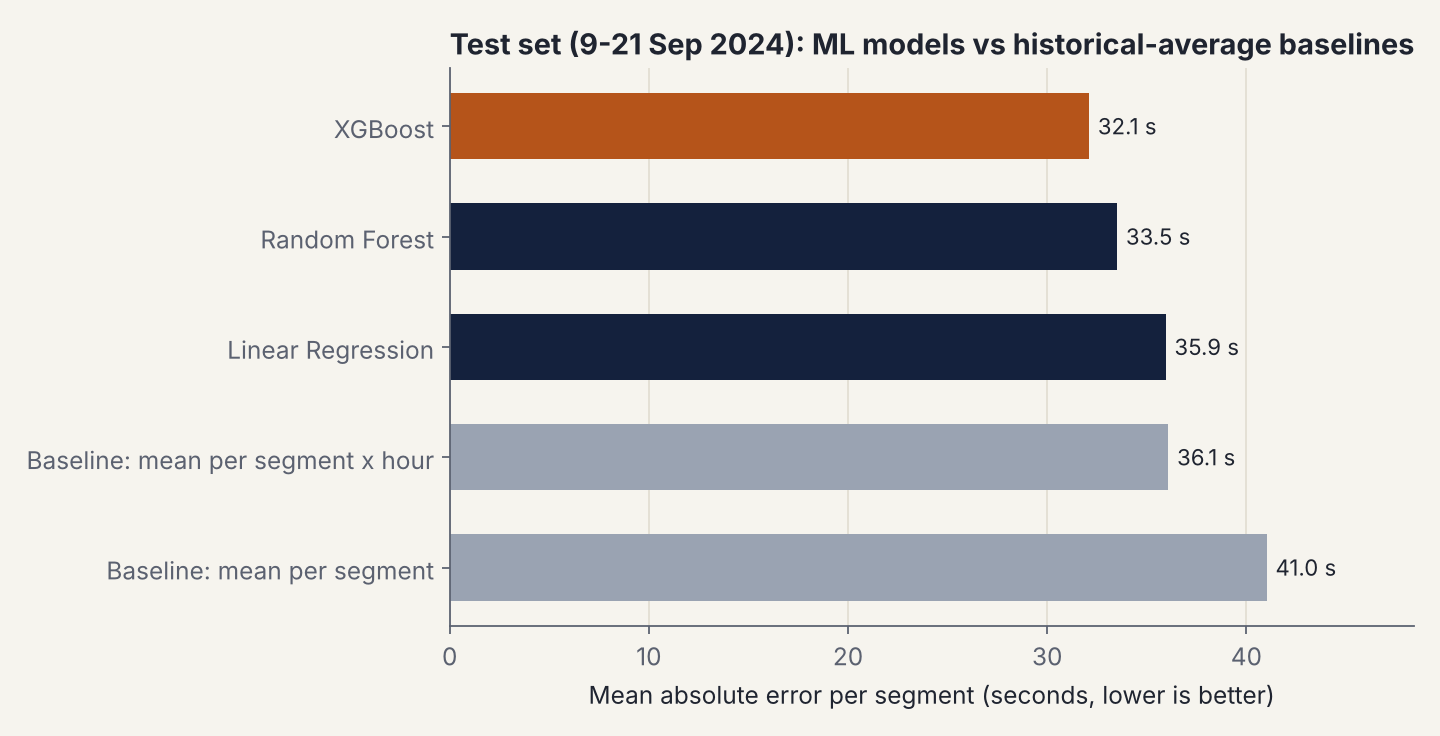

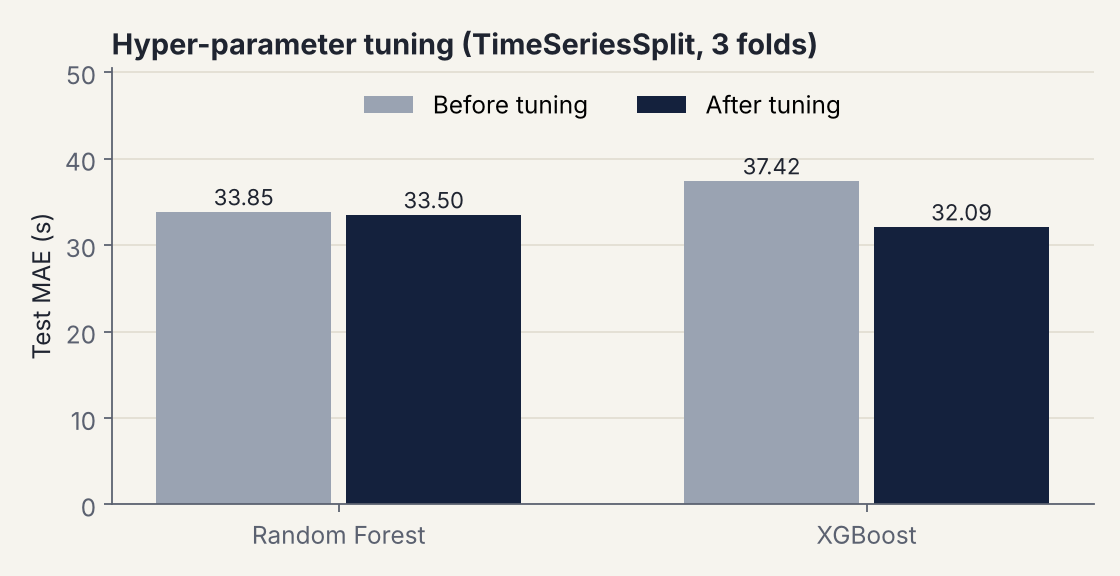

In [11]:
display(Image(REP / "mae_model_vs_baseline.png", width=750)); display(Image(REP / "tuning_before_after.png", width=560))

**Round 1 → Round 2.** Round 1 (20 features) gave XGBoost 32.13 s (+10.9%). Since that was under the 15% goal, round 2 added two real-time traffic features (route traffic in the last 15 min, this bus's delay so far). The row *XGBoost (round 1 features)* above is the same model with round-1 features on the same test set: the new features changed MAE by only ~0.03 s.

## 5. What a commuter feels: an 8-stop journey, everything frozen at the origin stop

In [12]:
pd.read_csv(REP / "results_journey_8stops.csv").round(2)

,model,MAE_s,RMSE_s,MAPE_%,R2,MAE_improvement_vs_best_baseline_%,n_journeys
0,Baseline: mean per segment,242.89,469.52,19.11,0.41,-18.17,21545
1,Baseline: mean per segment x hour,205.54,395.73,16.34,0.58,0.00,21545
2,Linear Regression,201.68,388.51,16.40,0.60,1.87,21545
3,Random Forest,187.34,362.99,15.40,0.65,8.86,21545
4,XGBoost,189.63,367.23,15.90,0.64,7.74,21545
5,XGBoost (round 1 features),188.98,379.95,14.79,0.62,8.05,21545


## 6. Classification: will this 8-stop journey be Late (> 1.2 × usual time)?

In [13]:
j = pd.read_parquet(DATA / "journeys.parquet"); jte = j[~j.is_train].copy()
jte["base_hour_ratio"] = jte.base_hour_sum / jte.base_sum
print(f"test journeys: {len(jte):,} | Late share: {jte.late.mean():.1%}")
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score
rows = {"Baseline: historical average (always On time)": np.zeros(len(jte), int)}
for name, f in [("Logistic Regression", "logistic_regression_late"), ("Random Forest Classifier", "random_forest_late")]:
    m = joblib.load(MOD / f"{f}.joblib"); rows[name] = m["model"].predict(jte[m["features"]])
pd.DataFrame({k: {"accuracy": accuracy_score(jte.late, v), "F1_late": f1_score(jte.late, v, zero_division=0),
                  "recall_late": recall_score(jte.late, v), "precision_late": precision_score(jte.late, v, zero_division=0)}
              for k, v in rows.items()}).T.round(3)

test journeys: 21,468 | Late share: 18.1%


,accuracy,F1_late,recall_late,precision_late
Baseline: historical average (always On time),0.819,0.000,0.000,0.000
Logistic Regression,0.752,0.496,0.673,0.392
Random Forest Classifier,0.816,0.574,0.682,0.495


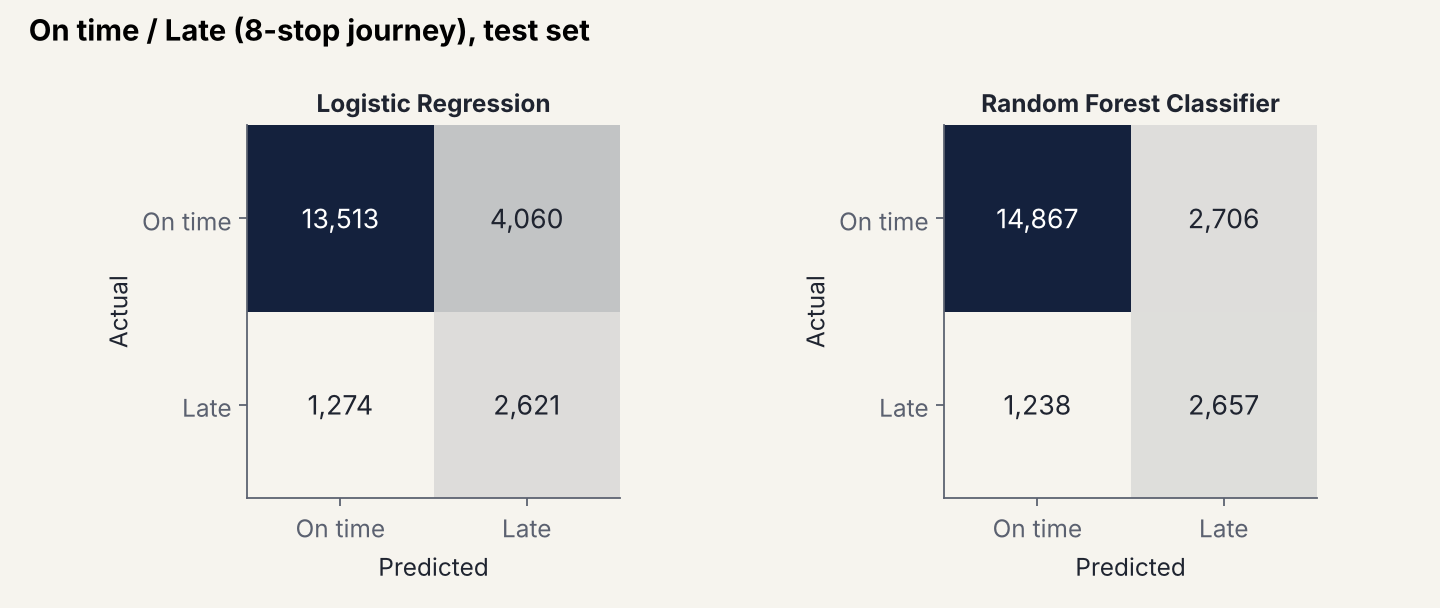

In [14]:
display(Image(REP / "confusion_matrices.png", width=720))

## 7. Feature importance and error analysis

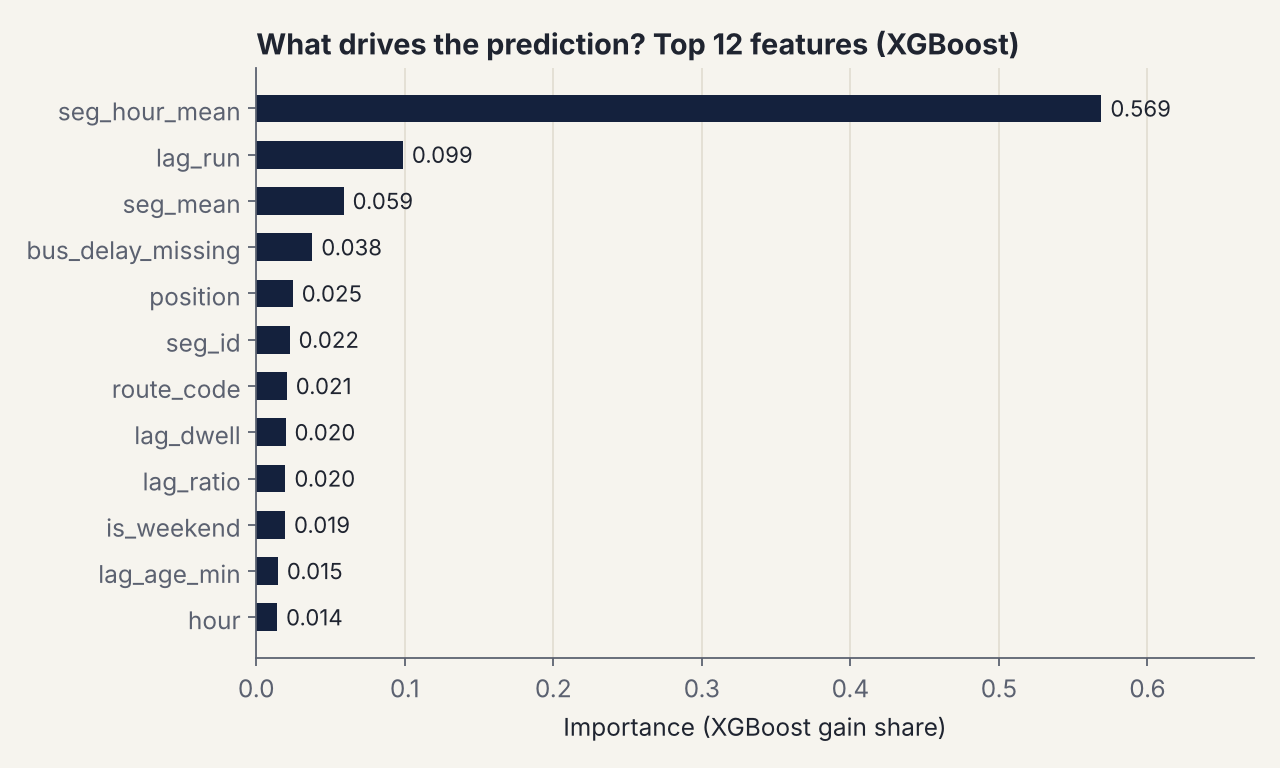

,feature,random_forest,xgboost
0,seg_hour_mean,0.3432,0.5690
1,lag_run,0.1931,0.0988
2,seg_mean,0.1515,0.0588
3,bus_delay_missing,0.0150,0.0378
4,position,0.0228,0.0246
5,seg_id,0.0726,0.0225
6,route_code,0.0035,0.0206
7,lag_dwell,0.0426,0.0198
8,lag_ratio,0.0327,0.0197
9,is_weekend,0.0026,0.0194


In [15]:
display(Image(REP / "feature_importance.png", width=640))
pd.read_csv(REP / "feature_importance.csv").head(10)

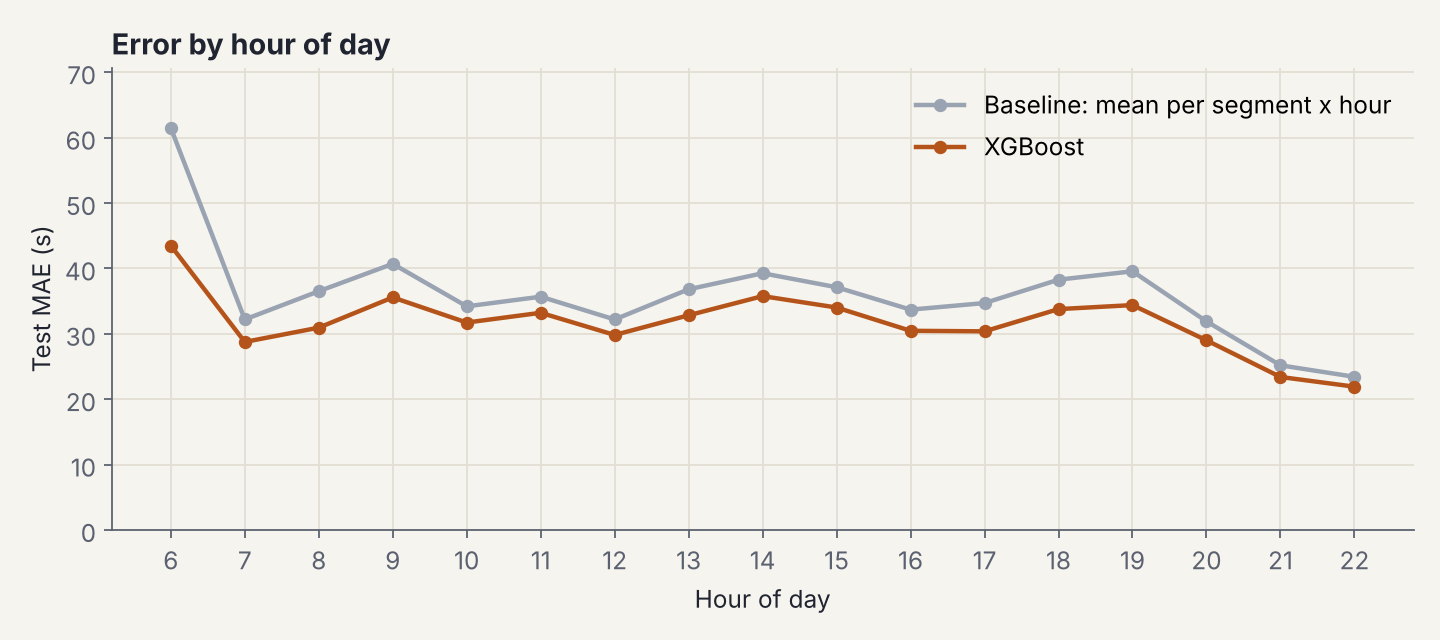

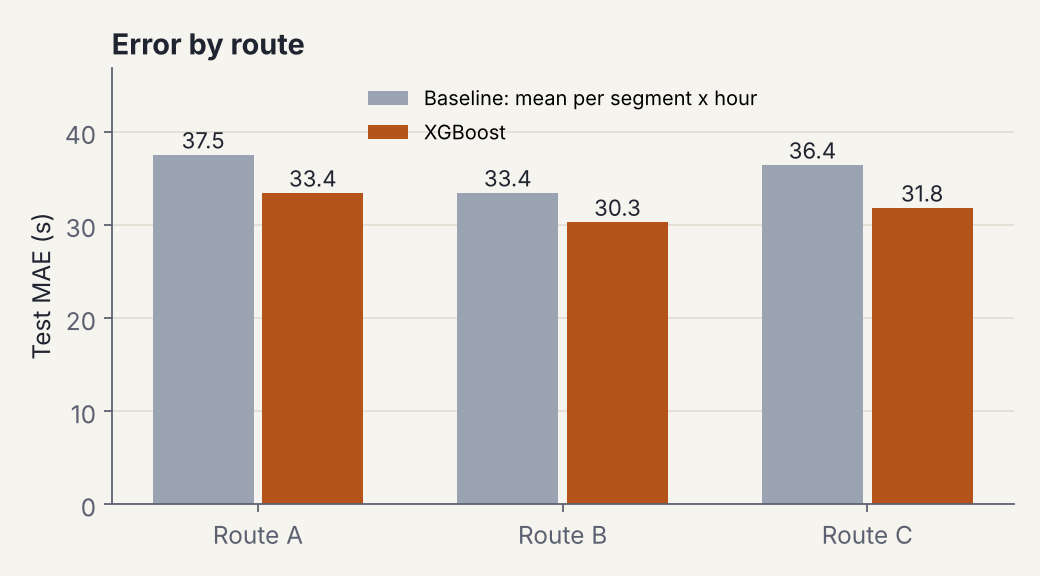

  route  MAE Baseline: mean per segment x hour  MAE XGBoost      n
0     A                                  37.52        33.42  82298
1     B                                  33.44        30.28  52283
2     C                                  36.43        31.82  53156
         is_rain  err_base  err_ml
no rain        0     36.06   32.02
rain           1     36.17   32.76


In [16]:
display(Image(REP / "error_by_hour.png", width=700)); display(Image(REP / "error_by_route.png", width=520))
print(pd.read_csv(REP / "error_by_route.csv"))
print(pd.read_csv(REP / "error_by_rain.csv").rename(index={0: "no rain", 1: "rain"}))

## 8. Conclusion

In [17]:
s = json.load(open(REP / "summary.json"))
print(f"Best non-AI baseline : {s['best_baseline']}  MAE {s['best_baseline_MAE_s']:.2f} s")
print(f"Best ML model        : {s['best_ml_model']}  MAE {s['best_ml_MAE_s']:.2f} s  -> {s['improvement_%']:.1f}% better")
print(f"15% goal met?        : {s['target_15pct_met']}")
print(f"8-stop journey       : baseline {s['journey_best_baseline_MAE_s']:.1f} s, Random Forest {s['journey_rf_MAE_s']:.1f} s, XGBoost {s['journey_xgb_MAE_s']:.1f} s")

Best non-AI baseline : Baseline: mean per segment x hour  MAE 36.07 s
Best ML model        : XGBoost  MAE 32.09 s  -> 11.0% better
15% goal met?        : False
8-stop journey       : baseline 205.5 s, Random Forest 187.3 s, XGBoost 189.6 s


**Answer to the research question: yes, but by less than we hoped.** On two unseen weeks, tuned XGBoost cuts the per-segment error by about 11% compared with the best historical-average method (segment × hour). Over an 8-stop trip, Random Forest cuts it by about 9%. The 15% goal was **not** met, and adding real-time traffic features did not change that. For *Late* detection, the historical average can never warn you (recall 0), while the Random Forest classifier catches about 68% of late journeys.

**Limitations:** Astana data, not Bangkok. Routes are inferred (A/B/C). No real traffic-speed feed. Grab / motorcycle-taxi time and cost are not modelled, and the recommendation is a fixed rule. The tuned XGBoost minimises absolute error, so it predicts the *typical* trip, which is shorter than the average because rare very slow trips pull the average up.